# 🔧 Notebook 02 — Feature Engineering Multi-Horizon
**Target Prediksi:** 60 menit, 180 menit, 360 menit ke depan

Pipeline: Load cleaned data → Feature Engineering → Train/Test Split → Simpan per horizon


In [1]:
# ── CELL 1: Import Library & Load Data Bersih ──────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json, os, warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)

df = pd.read_csv('dataset/data_cleaned.csv', parse_dates=['waktu_pembacaan'])
df = df.sort_values('waktu_pembacaan').reset_index(drop=True)

print('=== 📋 Data Bersih Dimuat ===')
print(f'Baris  : {len(df):,}')
print(f'Kolom  : {df.shape[1]}')
print(f'Periode: {df["waktu_pembacaan"].min()} → {df["waktu_pembacaan"].max()}')
print()
print(df.head(3))


=== 📋 Data Bersih Dimuat ===
Baris  : 90,720
Kolom  : 14
Periode: 2026-07-10 00:00:24 → 2026-09-10 23:59:55

   kelembaban_tanah_1  kelembaban_udara_1  tekanan_udara_1  suhu_udara_1  \
0                86.0               92.42         1013.875         23.86   
1                86.0               92.87         1013.904         23.86   
2                86.0               93.02         1013.914         23.92   

   kelembaban_tanah_2  kelembaban_udara_2  tekanan_udara_2  suhu_udara_2  \
0                91.0               99.60         1013.166         23.19   
1                91.0               99.60         1013.152         23.10   
2                91.0               99.55         1013.163         23.22   

   kelembaban_tanah_3  kelembaban_udara_3  tekanan_udara_3  suhu_udara_3  \
0                83.0                99.6         1013.694         22.69   
1                83.0                99.6         1013.703         22.73   
2                83.0                99.6         101

In [2]:
# ── CELL 2: Target Variable Multi-Horizon ──────────────────────
# Interval data = 1 menit → 60 langkah = 1 jam, 180 = 3 jam, 360 = 6 jam
print('=== 🎯 Membuat Target Multi-Horizon ===')

# Rata-rata kelembaban tanah 3 node (current)
df['kelembaban_tanah_avg'] = df[
    ['kelembaban_tanah_1','kelembaban_tanah_2','kelembaban_tanah_3']
].mean(axis=1)

HORIZONS = {
    '60m' : 60,   # 1 jam ke depan
    '180m': 180,  # 3 jam ke depan
    '360m': 360,  # 6 jam ke depan
}

for name, steps in HORIZONS.items():
    col = f'target_{name}'
    df[col] = df['kelembaban_tanah_avg'].shift(-steps)
    print(f'  {col}: prediksi {steps} menit ({steps//60} jam) ke depan')
    print(f'    mean={df[col].mean():.2f}%, std={df[col].std():.2f}%')

print()
print(df[['waktu_pembacaan','kelembaban_tanah_avg','target_60m','target_180m','target_360m']].head(5))


=== 🎯 Membuat Target Multi-Horizon ===
  target_60m: prediksi 60 menit (1 jam) ke depan
    mean=73.79%, std=6.22%
  target_180m: prediksi 180 menit (3 jam) ke depan
    mean=73.78%, std=6.20%
  target_360m: prediksi 360 menit (6 jam) ke depan
    mean=73.75%, std=6.18%

      waktu_pembacaan  kelembaban_tanah_avg  target_60m  target_180m  \
0 2026-07-10 00:00:24             86.666667   86.666667    86.666667   
1 2026-07-10 00:01:24             86.666667   87.000000    86.666667   
2 2026-07-10 00:02:24             86.666667   86.666667    86.666667   
3 2026-07-10 00:03:24             86.333333   86.666667    86.666667   
4 2026-07-10 00:04:24             86.333333   87.000000    87.000000   

   target_360m  
0    86.333333  
1    86.666667  
2    86.666667  
3    86.666667  
4    86.666667  


In [3]:
# ── CELL 3: Fitur Waktu ─────────────────────────────────────────
print('=== ⏱️  Membuat Fitur Waktu ===')

df['jam']         = df['waktu_pembacaan'].dt.hour
df['menit']       = df['waktu_pembacaan'].dt.minute
df['hari']        = df['waktu_pembacaan'].dt.day
df['bulan']       = df['waktu_pembacaan'].dt.month
df['hari_minggu'] = df['waktu_pembacaan'].dt.dayofweek
df['is_weekend']  = (df['hari_minggu'] >= 5).astype(int)

# Siklus sinus/kosinus untuk jam (menghindari diskontinuitas 23→0)
df['jam_sin'] = np.sin(2 * np.pi * df['jam'] / 24)
df['jam_cos'] = np.cos(2 * np.pi * df['jam'] / 24)

# Siklus bulan
df['bulan_sin'] = np.sin(2 * np.pi * df['bulan'] / 12)
df['bulan_cos'] = np.cos(2 * np.pi * df['bulan'] / 12)

# Periode hari: 0=malam, 1=pagi, 2=siang, 3=sore
df['periode_hari'] = pd.cut(df['jam'],
                             bins=[-1, 5, 11, 17, 23],
                             labels=[0, 1, 2, 3]).astype(int)

print('Fitur waktu: jam, menit, hari, bulan, hari_minggu, is_weekend,')
print('             jam_sin, jam_cos, bulan_sin, bulan_cos, periode_hari')


=== ⏱️  Membuat Fitur Waktu ===
Fitur waktu: jam, menit, hari, bulan, hari_minggu, is_weekend,
             jam_sin, jam_cos, bulan_sin, bulan_cos, periode_hari


In [4]:
# ── CELL 4: Lag Features (Extended) ────────────────────────────
print('=== 📋 Membuat Lag Features ===')

# Lag kelembaban tanah rata-rata — diperluas untuk horizon jauh
LAG_STEPS = [1, 5, 10, 30, 60, 120, 180, 360]
for lag in LAG_STEPS:
    df[f'kt_avg_lag_{lag}'] = df['kelembaban_tanah_avg'].shift(lag)

# Lag per-node (lag 1, 5, 60)
for node in [1, 2, 3]:
    col = f'kelembaban_tanah_{node}'
    for lag in [1, 5, 60]:
        df[f'kt{node}_lag_{lag}'] = df[col].shift(lag)

# Lag rata-rata udara & suhu (lag 1, 30, 60)
for feat in ['kelembaban_udara_1','suhu_udara_1','curah_hujan']:
    if feat in df.columns:
        for lag in [1, 30, 60]:
            safe = feat.replace('_1','')
            df[f'{safe}_lag_{lag}'] = df[feat].shift(lag)

print('Lag features dibuat untuk langkah:', LAG_STEPS)


=== 📋 Membuat Lag Features ===
Lag features dibuat untuk langkah: [1, 5, 10, 30, 60, 120, 180, 360]


In [5]:
# ── CELL 5: Rolling Statistics (Extended) ──────────────────────
print('=== 📊 Membuat Rolling Statistics ===')

WINDOWS = {'1jam': 60, '3jam': 180, '6jam': 360}

for wname, wsize in WINDOWS.items():
    s = df['kelembaban_tanah_avg'].shift(1)
    df[f'kt_roll_mean_{wname}'] = s.rolling(wsize, min_periods=10).mean()
    df[f'kt_roll_std_{wname}']  = s.rolling(wsize, min_periods=10).std()
    df[f'kt_roll_min_{wname}']  = s.rolling(wsize, min_periods=10).min()
    df[f'kt_roll_max_{wname}']  = s.rolling(wsize, min_periods=10).max()

    # Rolling curah hujan
    if 'curah_hujan' in df.columns:
        sh = df['curah_hujan'].shift(1)
        df[f'hujan_roll_sum_{wname}'] = sh.rolling(wsize, min_periods=1).sum()

    print(f'  Window {wname} ({wsize} langkah): mean, std, min, max, hujan_sum')

# Tren selisih
for d in [1, 5, 30, 60]:
    df[f'kt_avg_diff_{d}'] = df['kelembaban_tanah_avg'].diff(d)

print('Rolling statistics selesai')


=== 📊 Membuat Rolling Statistics ===
  Window 1jam (60 langkah): mean, std, min, max, hujan_sum
  Window 3jam (180 langkah): mean, std, min, max, hujan_sum
  Window 6jam (360 langkah): mean, std, min, max, hujan_sum
Rolling statistics selesai


In [6]:
# ── CELL 6: EWM Features & Interaksi ───────────────────────────
print('=== 🔗 Membuat EWM & Fitur Interaksi ===')

# Exponential Weighted Mean — sensitif terhadap tren terkini
for span in [12, 60, 180]:
    df[f'kt_ewm_{span}'] = (
        df['kelembaban_tanah_avg'].shift(1).ewm(span=span, adjust=False).mean()
    )
    print(f'  EWM span={span}')

# Rata-rata sensor udara & suhu (3 node)
ku_cols    = [c for c in df.columns if c.startswith('kelembaban_udara_')]
suhu_cols  = [c for c in df.columns if c.startswith('suhu_udara_')]
tek_cols   = [c for c in df.columns if c.startswith('tekanan_udara_')]

if ku_cols:
    df['ku_avg']      = df[ku_cols].mean(axis=1)
if suhu_cols:
    df['suhu_avg']    = df[suhu_cols].mean(axis=1)
if tek_cols:
    df['tekanan_avg'] = df[tek_cols].mean(axis=1)

# Vapor Pressure Deficit (VPD) — indikator evapotranspirasi
for i in [1, 2, 3]:
    ku  = f'kelembaban_udara_{i}'
    su  = f'suhu_udara_{i}'
    if ku in df.columns and su in df.columns:
        df[f'vpd_{i}'] = (
            (1 - df[ku]/100) * 0.6108 *
            np.exp(17.27 * df[su] / (df[su] + 237.3))
        )
if all(f'vpd_{i}' in df.columns for i in [1,2,3]):
    df['vpd_avg'] = df[['vpd_1','vpd_2','vpd_3']].mean(axis=1)

# Perbedaan antar node (spatial variability)
kt_cols_node = ['kelembaban_tanah_1','kelembaban_tanah_2','kelembaban_tanah_3']
if all(c in df.columns for c in kt_cols_node):
    df['kt_diff_12'] = df['kelembaban_tanah_1'] - df['kelembaban_tanah_2']
    df['kt_diff_13'] = df['kelembaban_tanah_1'] - df['kelembaban_tanah_3']
    df['kt_diff_23'] = df['kelembaban_tanah_2'] - df['kelembaban_tanah_3']

print('EWM, VPD, ku_avg, suhu_avg, tekanan_avg, kt_diff selesai dibuat')


=== 🔗 Membuat EWM & Fitur Interaksi ===
  EWM span=12
  EWM span=60
  EWM span=180
EWM, VPD, ku_avg, suhu_avg, tekanan_avg, kt_diff selesai dibuat


In [7]:
# ── CELL 7: Finalisasi & Simpan per Horizon ────────────────────
import json, os

os.makedirs('dataset', exist_ok=True)
os.makedirs('models',  exist_ok=True)

HORIZONS = {'60m': 60, '180m': 180, '360m': 360}

# Kolom yang BUKAN fitur dan BUKAN target
META_COLS    = ['waktu_pembacaan']
TARGET_COLS  = [f'target_{h}' for h in HORIZONS]

for horizon, steps in HORIZONS.items():
    target = f'target_{horizon}'

    # Kolom fitur = semua kecuali meta + semua target lain
    excl = set(META_COLS + TARGET_COLS)
    feat_cols = [c for c in df.columns if c not in excl]

    # Filter baris: harus ada target + tidak ada NaN di fitur
    df_h = df[META_COLS + feat_cols + [target]].copy()
    n_before = len(df_h)
    df_h = df_h.dropna(subset=[target])
    df_h = df_h.dropna()
    n_after = len(df_h)

    print(f'\n=== Horizon {horizon} ===')
    print(f'  Baris : {n_before:,} → {n_after:,} (hapus {n_before-n_after:,} NaN)')
    print(f'  Fitur : {len(feat_cols)}')

    # Downcasting ke float32 untuk hemat memori
    for col in feat_cols:
        if df_h[col].dtype == 'float64':
            df_h[col] = df_h[col].astype('float32')

    # Train/test split 80/20 kronologis
    split_idx = int(len(df_h) * 0.8)
    df_train  = df_h.iloc[:split_idx]
    df_test   = df_h.iloc[split_idx:]

    print(f'  Train : {len(df_train):,} | Test: {len(df_test):,}')

    # Simpan
    df_train.to_csv(f'dataset/data_train_{horizon}.csv', index=False)
    df_test.to_csv( f'dataset/data_test_{horizon}.csv',  index=False)
    df_h.to_csv(    f'dataset/data_features_{horizon}.csv', index=False)

    with open(f'models/feature_cols_{horizon}.json', 'w') as f:
        json.dump(feat_cols, f, indent=2)

    print(f'  [OK] Disimpan: data_train_{horizon}.csv, data_test_{horizon}.csv')

print('\n[OK] Feature engineering selesai! Lanjut ke → 03_random_forest.ipynb')



=== Horizon 60m ===
  Baris : 90,720 → 90,300 (hapus 420 NaN)
  Fitur : 83
  Train : 72,240 | Test: 18,060
  [OK] Disimpan: data_train_60m.csv, data_test_60m.csv

=== Horizon 180m ===
  Baris : 90,720 → 90,180 (hapus 540 NaN)
  Fitur : 83
  Train : 72,144 | Test: 18,036
  [OK] Disimpan: data_train_180m.csv, data_test_180m.csv

=== Horizon 360m ===
  Baris : 90,720 → 90,000 (hapus 720 NaN)
  Fitur : 83
  Train : 72,000 | Test: 18,000
  [OK] Disimpan: data_train_360m.csv, data_test_360m.csv

[OK] Feature engineering selesai! Lanjut ke → 03_random_forest.ipynb


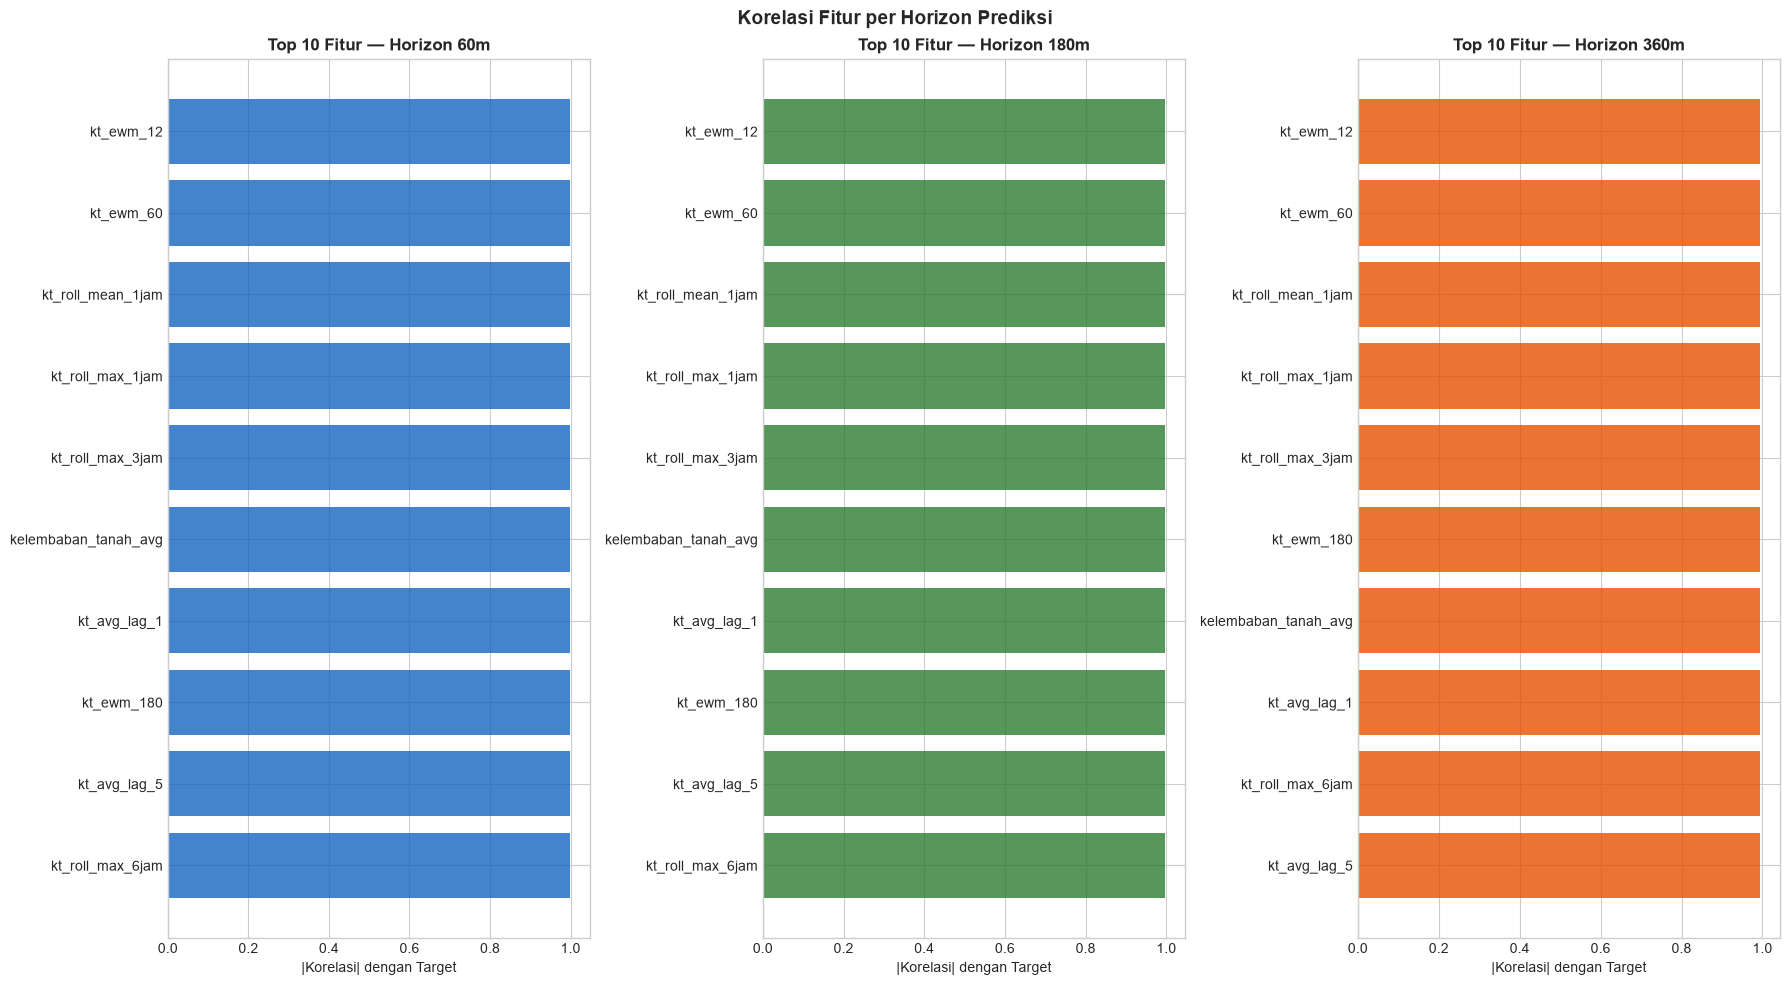

[OK] Plot korelasi multi-horizon disimpan


In [8]:
# ── CELL 8: Visualisasi Korelasi & Train-Test Split ────────────
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(18, 10))
gs  = GridSpec(1, 3, figure=fig)

colors_h = {'60m': '#1565C0', '180m': '#2E7D32', '360m': '#E65100'}

for idx, (horizon, color) in enumerate(colors_h.items()):
    ax = fig.add_subplot(gs[idx])
    target = f'target_{horizon}'
    df_tmp = df[['waktu_pembacaan', target]].dropna()

    feat_tmp = [c for c in df.columns if c not in
                ['waktu_pembacaan'] + [f'target_{h}' for h in HORIZONS]]
    corr = df[feat_tmp + [target]].corr()[target].drop(target).abs()
    top10 = corr.sort_values(ascending=False).head(10)

    ax.barh(top10.index[::-1], top10.values[::-1], color=color, alpha=0.8)
    ax.set_title(f'Top 10 Fitur — Horizon {horizon}', fontweight='bold')
    ax.set_xlabel('|Korelasi| dengan Target')

fig.suptitle('Korelasi Fitur per Horizon Prediksi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('dataset/plot_korelasi_multihorizon.png', dpi=150, bbox_inches='tight')
plt.show()
print('[OK] Plot korelasi multi-horizon disimpan')
